In [1]:
import torch
import os
import pickle
import numpy as np
import pandas as pd
import folium
from branca.colormap import LinearColormap
from numpy.lib.stride_tricks import sliding_window_view
from typing import Literal
import matplotlib.pyplot as plt

from src.utils.loading.checkpoint_loading import load_nn_checkpoint, load_lgbm_checkpoint, load_test_results
from src.model.baseline_temporal_models.encoder_decoder_gru import EncoderDecoderGRU, EncoderDecoderGRUConfig
from src.model.baseline_temporal_models.gru import GRU, GRUConfig
from src.model.baseline_temporal_models.mlp import MLP, MLPConfig
from src.model.baseline_temporal_models.lgbm import LGBM, LGBMConfig
from src.utils.metrics.metrics import masked_mae


In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


In [3]:
def get_per_sensor_loss(folder_path):
    inputs, predictions, targets = load_test_results(folder_path)
    _, _, S = inputs.shape
    per_sensor_loss = []
    for i in range(S):
        per_sensor_loss.append(
            masked_mae(
                torch.tensor(predictions[:, :, i]),
                torch.tensor(targets[:, :, i])
            )
        )
    return per_sensor_loss

In [21]:
def get_per_time_loss(folder_path, type: Literal["tod", "dow"]):
    inputs, predictions, targets = load_test_results(folder_path)
    N, input_len, S = inputs.shape
    output_len = predictions.shape[1]
    
    timestamps = np.load("data/METR-LA/test_timestamps.npy")  # (T, 2)
    timestamps = sliding_window_view(timestamps, input_len + output_len, axis=0)
    tod = np.round(timestamps[..., 0, input_len:] * 288).astype(int)
    dow = np.round(timestamps[..., 1, input_len:] * 7).astype(int)
    if type == "tod":
        n = 288
        ts = tod
    else:
        n = 7
        ts = dow
    ts = np.broadcast_to(ts.reshape(N, output_len, 1), (N, output_len, S)) # shape (N, L, S)
    ans = []
    predictions  = torch.tensor(predictions)
    targets = torch.tensor(targets)
    for t in range(n):
        m = ts == t
        loss = masked_mae(predictions[m], targets[m]).item()
        ans.append(loss)

    return ans

In [5]:

def plot_sensor_loss(per_sensor_loss, data_path="data/METR-LA"):
    loss = np.array([float(x) for x in per_sensor_loss], dtype=np.float64)
    with open(os.path.join(data_path, "adj_mx.pkl"), "rb") as f:
        sensor_ids, _, _ = pickle.load(f, encoding="latin1")
    if len(loss) != len(sensor_ids):
        raise ValueError(f"expected {len(sensor_ids)} sensor losses, got {len(loss)}")

    loc = pd.read_csv(os.path.join(data_path, "graph_sensor_locations.csv"))
    loc = loc.set_index(loc["sensor_id"].astype(str)).loc[[str(s) for s in sensor_ids]].reset_index(drop=True)

    lo, hi = float(loss.min()), float(loss.max())
    cmap = LinearColormap(["green", "red"], vmin=lo, vmax=hi if hi > lo else lo + 1.0)
    cmap.caption = "per-sensor loss"

    m = folium.Map(location=[loc.latitude.mean(), loc.longitude.mean()], zoom_start=11, tiles="OpenStreetMap")
    m.fit_bounds([[loc.latitude.min(), loc.longitude.min()], [loc.latitude.max(), loc.longitude.max()]])
    for i, sensor_id in enumerate(sensor_ids):
        color = cmap(loss[i])
        folium.CircleMarker(
            location=[float(loc.latitude[i]), float(loc.longitude[i])],
            radius=6,
            color=color,
            fill=True,
            fill_color=color,
            fill_opacity=0.85,
            tooltip=f"sensor {sensor_id} (idx {i})<br>loss {loss[i]:.3f}",
        ).add_to(m)
    cmap.add_to(m)
    return m

In [12]:
def plot_time_loss(loss):
    kind = len(loss)
    if kind == 288:
        plt.plot(np.arange(288) / 12, loss)
        plt.xlabel("hour of day")
        plt.xticks(range(0, 25, 2))
    else:
        plt.bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], loss)
        plt.xlabel("day of week")
    plt.ylabel("MAE")
    plt.show()


# Per Sensor Loss Analysis

In [7]:
# 1. Best performing vector-output GRU model -> input_len = 12, use_tod = True
plot_sensor_loss(get_per_sensor_loss("checkpoints/GRU/None_10_12_12/input_12_tod"))

In [ ]:
# 2. Best performing encoder-decoder GRU model -> input_len = 12, use_tod = True, autoregressive trained
plot_sensor_loss(get_per_sensor_loss("checkpoints/EncoderDecoderGRU/None_10_12_12/input_12_autoregressive_tod"))

In [ ]:
# 3. Best performing MLP model -> input_len = 12, use_tod = True
plot_sensor_loss(get_per_sensor_loss("checkpoints/MLP/None_10_12_12/input_12_tod"))

In [ ]:
# 4. Best performing LGBM model -> 1000 estimators (hyperparameter fine-tuned), use_tod=True

# load models
lgbm_models = load_lgbm_checkpoint("checkpoints/LGBM/tuning")
input_len = 12
output_len = 12

# data
data = np.load("data/METR-LA/test_data.npy").astype(np.float32) 
w = sliding_window_view(data, input_len + output_len, axis=0)  # (T', N, L + H)
S = w.shape[1]
X = w[..., :input_len].reshape(-1, input_len).copy()
Y = w[..., input_len:].reshape(-1, output_len).copy()

# tod timestamps
ts = np.load("data/METR-LA/test_timestamps.npy").astype(np.float32) 
encoded_ts = []
encoded_ts.append(np.sin(2 * np.pi * ts[:, 0]))
encoded_ts.append(np.cos(2 * np.pi * ts[:, 0]))
ts = np.stack(encoded_ts, axis=-1)
ts = sliding_window_view(ts, input_len + output_len, axis=0)
X_ts = ts[..., :input_len].copy()
T, F, L = X_ts.shape
X_ts = np.permute_dims(X_ts, (0, 2, 1)).reshape((T, 1, L, F)) 
X_ts = np.broadcast_to(X_ts, (T, S, L, F)).reshape(T * S, L * F)

X = np.concat([X, X_ts], axis=-1)

predictions = [model.predict(X) for model in lgbm_models]
Y = Y[:, [2, 5, 11]]

Y = Y.reshape(T, S, 3).transpose(0, 2, 1)
predictions = np.stack([
    p.reshape(T, S) for p in predictions
], axis=1)
# both Y and predictions have shape (T, 3, S) now

per_sensor_loss = []
for i in range(S):
    per_sensor_loss.append(
        masked_mae(
            torch.tensor(predictions[:, :, i]),
            torch.tensor(Y[:, :, i])
        )
    )
plot_sensor_loss(per_sensor_loss)

[LightGBM] [Warning] bagging_freq is set=2, subsample_freq=0 will be ignored. Current value: bagging_freq=2
[LightGBM] [Warning] feature_fraction is set=0.7587948587257435, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.7587948587257435
[LightGBM] [Warning] bagging_fraction is set=0.7135681866731614, subsample=1.0 will be ignored. Current value: bagging_fraction=0.7135681866731614
[LightGBM] [Warning] bagging_freq is set=2, subsample_freq=0 will be ignored. Current value: bagging_freq=2
[LightGBM] [Warning] feature_fraction is set=0.7587948587257435, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.7587948587257435
[LightGBM] [Warning] bagging_fraction is set=0.7135681866731614, subsample=1.0 will be ignored. Current value: bagging_fraction=0.7135681866731614
[LightGBM] [Warning] bagging_freq is set=2, subsample_freq=0 will be ignored. Current value: bagging_freq=2
[LightGBM] [Warning] feature_fraction is set=0.7587948587257435, colsample

# Per Time Loss Analysis

In [11]:
tod = "tod"
dow = "dow"

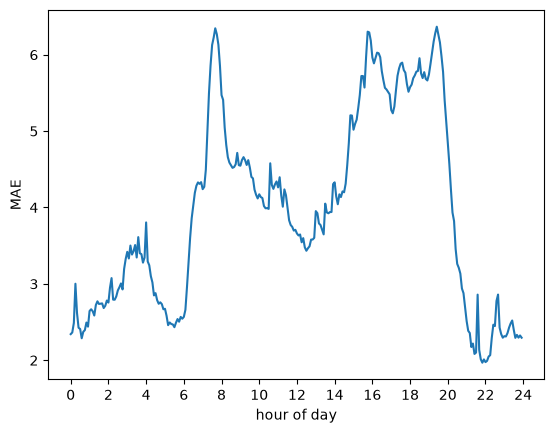

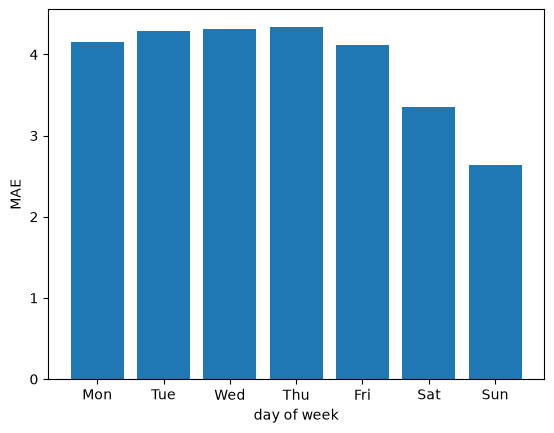

In [22]:
# 1. Best performing vector-output GRU model -> input_len = 12, use_tod = True
plot_time_loss(get_per_time_loss("checkpoints/GRU/None_10_12_12/input_12_tod", tod))
plot_time_loss(get_per_time_loss("checkpoints/GRU/None_10_12_12/input_12_tod", dow))

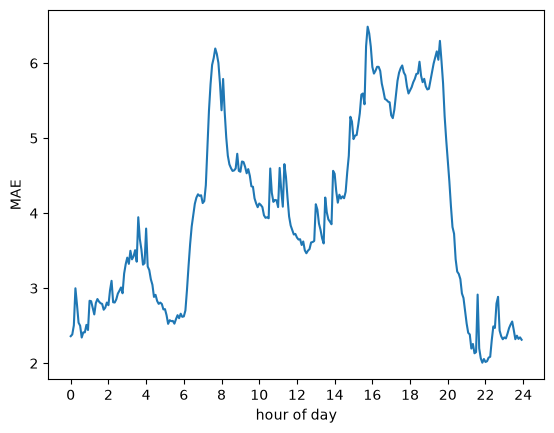

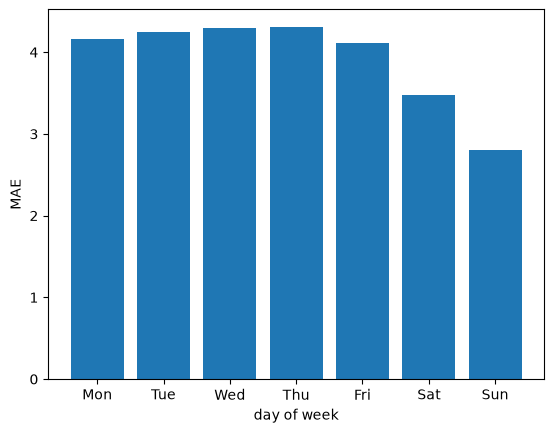

In [15]:
# 2. Best performing encoder-decoder GRU model -> input_len = 12, use_tod = True, autoregressive trained
plot_time_loss(get_per_time_loss("checkpoints/EncoderDecoderGRU/None_10_12_12/input_12_autoregressive_tod", tod))
plot_time_loss(get_per_time_loss("checkpoints/EncoderDecoderGRU/None_10_12_12/input_12_autoregressive_tod", dow))

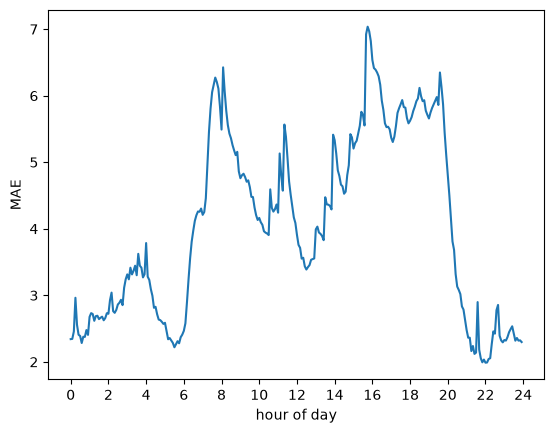

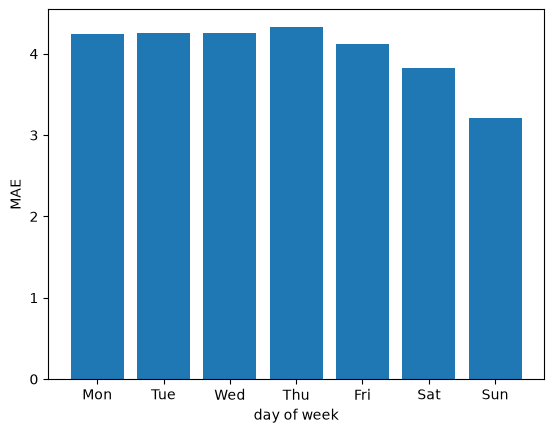

In [16]:
# 3. Best performing MLP model -> input_len = 12, use_tod = True
plot_time_loss(get_per_time_loss("checkpoints/MLP/None_10_12_12/input_12_tod", tod))
plot_time_loss(get_per_time_loss("checkpoints/MLP/None_10_12_12/input_12_tod", dow))

[LightGBM] [Warning] bagging_freq is set=2, subsample_freq=0 will be ignored. Current value: bagging_freq=2
[LightGBM] [Warning] feature_fraction is set=0.7587948587257435, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.7587948587257435
[LightGBM] [Warning] bagging_fraction is set=0.7135681866731614, subsample=1.0 will be ignored. Current value: bagging_fraction=0.7135681866731614
[LightGBM] [Warning] bagging_freq is set=2, subsample_freq=0 will be ignored. Current value: bagging_freq=2
[LightGBM] [Warning] feature_fraction is set=0.7587948587257435, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.7587948587257435
[LightGBM] [Warning] bagging_fraction is set=0.7135681866731614, subsample=1.0 will be ignored. Current value: bagging_fraction=0.7135681866731614
[LightGBM] [Warning] bagging_freq is set=2, subsample_freq=0 will be ignored. Current value: bagging_freq=2
[LightGBM] [Warning] feature_fraction is set=0.7587948587257435, colsample

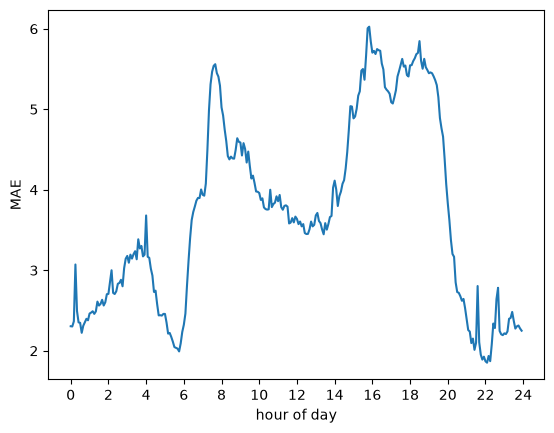

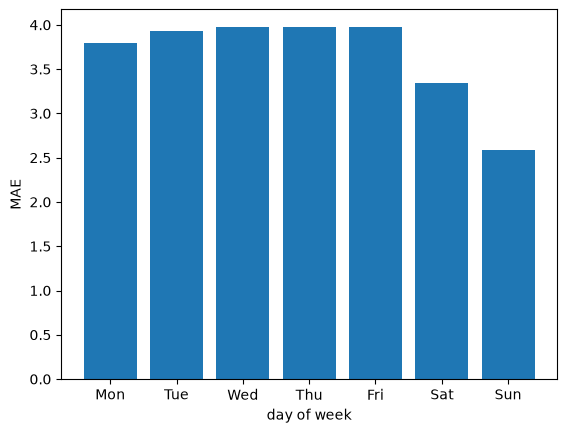

In [30]:
# 4. Best performing LGBM model -> 1000 estimators (hyperparameter fine-tuned), use_tod=True

# load models
lgbm_models = load_lgbm_checkpoint("checkpoints/LGBM/tuning")
input_len = 12
output_len = 12

# timestamps
timestamps = np.load("data/METR-LA/test_timestamps.npy").astype(np.float32) 
ts = sliding_window_view(timestamps, input_len + output_len, axis=0)
N = ts.shape[0]
tod = np.round(ts[..., 0, input_len:] * 288).astype(int)
dow = np.round(ts[..., 1, input_len:] * 7).astype(int)

output_tod = np.broadcast_to(tod.reshape(N, output_len, 1)[:, [2, 5, 11], :], (N, 3, S)) # shape (N, 3, S)
output_dow = np.broadcast_to(dow.reshape(N, output_len, 1)[:, [2, 5, 11], :], (N, 3, S)) # shape (N, 3, S)

# data
data = np.load("data/METR-LA/test_data.npy").astype(np.float32) 
w = sliding_window_view(data, input_len + output_len, axis=0)  # (T', N, L + H)
S = w.shape[1]
X = w[..., :input_len].reshape(-1, input_len).copy()
N = X.shape[0]
Y = w[..., input_len:].reshape(-1, output_len).copy()

# encoded tod timestamps
encoded_ts = []
encoded_ts.append(np.sin(2 * np.pi * timestamps[:, 0]))
encoded_ts.append(np.cos(2 * np.pi * timestamps[:, 0]))
ts = np.stack(encoded_ts, axis=-1)
ts = sliding_window_view(ts, input_len + output_len, axis=0)
X_ts = ts[..., :input_len].copy()
T, F, L = X_ts.shape
X_ts = np.permute_dims(X_ts, (0, 2, 1)).reshape((T, 1, L, F)) 
X_ts = np.broadcast_to(X_ts, (T, S, L, F)).reshape(T * S, L * F)

X = np.concat([X, X_ts], axis=-1)

predictions = [model.predict(X) for model in lgbm_models]
Y = Y[:, [2, 5, 11]]

Y = Y.reshape(T, S, 3).transpose(0, 2, 1)
predictions = np.stack([
    p.reshape(T, S) for p in predictions
], axis=1)
# both Y and predictions have shape (T, 3, S) now
ans = []
predictions  = torch.tensor(predictions)
targets = torch.tensor(Y)
for t in range(288):
    m = output_tod == t
    ans.append(masked_mae(predictions[m], targets[m]).item())
plot_time_loss(ans)
ans = []
for t in range(7):
    m = output_dow == t
    ans.append(masked_mae(predictions[m], targets[m]).item())
plot_time_loss(ans)
plot_sensor_loss(per_sensor_loss)